# Metode Morphology pada Pengolahan Citra Digital

---

## 1. Pendahuluan Morphology

Morphology adalah teknik pengolahan citra yang berbasis **bentuk (shape)** objek. Operasi morfologi umumnya diterapkan pada **citra biner**, namun juga dapat diperluas pada citra grayscale.

Tujuan utama:

* Menghilangkan noise
* Memperbaiki bentuk objek
* Ekstraksi fitur bentuk
* Segmentasi objek

---

## 2. Contoh Citra Biner

Citra biner hanya memiliki dua nilai piksel:

* 1 (Putih / objek)
* 0 (Hitam / background)

Contoh matriks biner:

```
0 0 0 0 0
0 1 1 1 0
0 1 1 1 0
0 0 0 0 0
```

---

## 3. Konektivitas Piksel

### 4-Connectivity

Tetangga piksel:

* atas
* bawah
* kiri
* kanan

### 8-Connectivity

Termasuk diagonal:

* kiri atas
* kanan atas
* kiri bawah
* kanan bawah

Digunakan untuk analisis komponen terhubung.

---

## 4. Operator Aditif dan Subtraktif

### Operator Aditif

Menambahkan piksel objek.
Contoh: **Dilasi**

### Operator Subtraktif

Mengurangi piksel objek.
Contoh: **Erosi**

---

## 5. Himpunan Translasi dan Refleksi

### Translasi

Perpindahan posisi himpunan piksel:

A + z = {a + z | a ∈ A}

### Refleksi

Pembalikan structuring element terhadap origin.

B^ = {-b | b ∈ B}

Digunakan dalam formulasi umum operasi morfologi.

---

## 6. Elemen Penstruktur (Structuring Element) B

Structuring Element (SE) adalah kernel kecil yang menentukan operasi morfologi.

Contoh:

```
1 1 1
1 1 1
1 1 1
```

Jenis umum:

* Square
* Disk
* Cross
* Line

---

## 7. Dilasi (Dilation)

Dilasi memperbesar objek.

Rumus:

A ⊕ B = { z | (B^)z ∩ A ≠ ∅ }

### Implementasi Python

```python
import cv2
import numpy as np

img = cv2.imread('binary.png',0)
_, binary = cv2.threshold(img,127,255,cv2.THRESH_BINARY)

kernel = np.ones((3,3),np.uint8)
dilation = cv2.dilate(binary,kernel,iterations=1)
```

---

## 8. Erosi (Erosion)

Erosi mengecilkan objek.

Rumus:

A ⊖ B = { z | Bz ⊆ A }

```python
erosion = cv2.erode(binary,kernel,iterations=1)
```

---

## 9. Opening Operator

Opening = Erosi → Dilasi

Fungsi:

* Menghilangkan noise kecil
* Memisahkan objek tipis

```python
opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
```

---

## 10. Closing Operator

Closing = Dilasi → Erosi

Fungsi:

* Menutup lubang kecil
* Menyatukan objek berdekatan

```python
closing = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)
```

---

## 11. Template Matching Morphology

Template matching morfologi digunakan untuk mendeteksi pola tertentu menggunakan structuring element khusus.

Contoh penggunaan:

* Deteksi bentuk huruf
* Deteksi sudut

```python
result = cv2.matchTemplate(binary, template, cv2.TM_CCOEFF)
```

---

## 12. Hit-or-Miss Transform

Operator untuk mendeteksi pola spesifik pada citra biner.

Rumus:

A ⊗ B = (A ⊖ B1) ∩ (Ac ⊖ B2)

Digunakan untuk:

* Deteksi ujung garis
* Deteksi sudut
* Skeleton analysis

```python
kernel = np.array([[1,1,1],[0,1,0],[-1,-1,-1]], dtype=np.int8)
hitmiss = cv2.morphologyEx(binary, cv2.MORPH_HITMISS, kernel)
```

---

## 13. Boundary Extraction

Mengambil batas objek.

Rumus:

Boundary(A) = A − (A ⊖ B)

```python
eroded = cv2.erode(binary,kernel)
boundary = binary - eroded
```

---

## 14. Thinning

Mengurangi objek menjadi skeleton tanpa merusak struktur.

Digunakan pada:

* OCR
* Fingerprint recognition
* Analisis bentuk

```python
import cv2.ximgproc as ximgproc
thin = ximgproc.thinning(binary)
```

---

## 15. Contoh Workflow Lengkap Morphology

```python
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.subplot(231); plt.imshow(binary, cmap='gray'); plt.title('Binary')
plt.subplot(232); plt.imshow(dilation, cmap='gray'); plt.title('Dilation')
plt.subplot(233); plt.imshow(erosion, cmap='gray'); plt.title('Erosion')
plt.subplot(234); plt.imshow(opening, cmap='gray'); plt.title('Opening')
plt.subplot(235); plt.imshow(closing, cmap='gray'); plt.title('Closing')
plt.subplot(236); plt.imshow(boundary, cmap='gray'); plt.title('Boundary')
plt.show()
```

---

## 16. Ringkasan Operasi Morphology

| Operasi             | Fungsi            |
| ------------------- | ----------------- |
| Dilasi              | Memperbesar objek |
| Erosi               | Mengecilkan objek |
| Opening             | Hapus noise kecil |
| Closing             | Tutup lubang      |
| Hit-or-Miss         | Deteksi pola      |
| Boundary Extraction | Ambil tepi objek  |
| Thinning            | Skeletonisasi     |

---

## **Visualisasi Step-by-Step Operasi Morphology**

### **1. Citra Awal (Binary Image)**

```python
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Membuat citra biner sederhana
image = np.zeros((10,10), dtype=np.uint8)
image[3:7,3:7] = 255

plt.imshow(image, cmap='gray')
plt.title('Citra Biner Awal')
plt.axis('off')
plt.show()
```

---

### **2. Structuring Element (Elemen Penstruktur)**

```python
kernel = np.ones((3,3), np.uint8)
print(kernel)
```

Mahasiswa dapat mencoba ukuran kernel berbeda:

* 3×3
* 5×5
* bentuk cross

---

### **3. Dilasi (Step-by-Step)**

```python
dilation = cv2.dilate(image, kernel, iterations=1)

plt.figure(figsize=(8,4))
plt.subplot(1,2,1)
plt.imshow(image, cmap='gray')
plt.title('Original')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(dilation, cmap='gray')
plt.title('Dilasi')
plt.axis('off')
plt.show()
```

**Observasi:**

* Objek menjadi lebih besar
* Lubang kecil tertutup

---

### **4. Erosi (Step-by-Step)**

```python
erosion = cv2.erode(image, kernel, iterations=1)

plt.figure(figsize=(8,4))
plt.subplot(1,2,1)
plt.imshow(image, cmap='gray')
plt.title('Original')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(erosion, cmap='gray')
plt.title('Erosi')
plt.axis('off')
plt.show()
```

**Observasi:**

* Objek mengecil
* Noise kecil hilang

---

### **5. Opening (Erosi → Dilasi)**

```python
opening = cv2.morphologyEx(image, cv2.MORPH_OPEN, kernel)

plt.figure(figsize=(12,4))
plt.subplot(1,3,1)
plt.imshow(image, cmap='gray')
plt.title('Original')
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(erosion, cmap='gray')
plt.title('Step 1: Erosi')
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(opening, cmap='gray')
plt.title('Opening')
plt.axis('off')
plt.show()
```

**Fungsi:** Menghilangkan noise kecil tanpa merusak bentuk utama objek.

---

### **6. Closing (Dilasi → Erosi)**

```python
closing = cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel)

plt.figure(figsize=(12,4))
plt.subplot(1,3,1)
plt.imshow(image, cmap='gray')
plt.title('Original')
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(dilation, cmap='gray')
plt.title('Step 1: Dilasi')
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(closing, cmap='gray')
plt.title('Closing')
plt.axis('off')
plt.show()
```

**Fungsi:** Menutup celah atau lubang kecil pada objek.

---

### **7. Boundary Extraction**

```python
boundary = image - erosion

plt.imshow(boundary, cmap='gray')
plt.title('Boundary Extraction')
plt.axis('off')
plt.show()
```

Menampilkan hanya batas objek.

---

### **8. Thinning (Skeletonization)**

```python
from skimage.morphology import skeletonize

binary = image > 0
skeleton = skeletonize(binary)

plt.figure(figsize=(8,4))
plt.subplot(1,2,1)
plt.imshow(binary, cmap='gray')
plt.title('Binary')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(skeleton, cmap='gray')
plt.title('Thinning / Skeleton')
plt.axis('off')
plt.show()
```

Menghasilkan representasi rangka objek satu piksel.

---

### **9. Kesimpulan Visualisasi**

* Dilasi memperbesar objek.
* Erosi memperkecil objek.
* Opening efektif untuk menghilangkan noise.
* Closing memperbaiki lubang objek.
* Boundary extraction mengekstrak tepi objek.
* Thinning menghasilkan skeleton untuk analisis bentuk.


## Eksperimen Parameter Structuring Element

### Praktikum Pengolahan Citra Digital

Dokumen ini dapat **langsung di-copy** ke dalam **Jupyter Notebook (.ipynb)**.

---

### 1. Import Library

```python
import cv2
import numpy as np
import matplotlib.pyplot as plt
```

---

### 2. Membuat Dataset Uji (Binary Image + Noise)

```python
img = np.zeros((120,120), dtype=np.uint8)

# objek utama
cv2.circle(img,(60,60),30,255,-1)
cv2.rectangle(img,(20,80),(40,100),255,-1)

# tambah noise
noise = np.random.randint(0,2,(120,120))*255
img_noisy = cv2.bitwise_or(img, noise.astype(np.uint8))

plt.figure(figsize=(4,4))
plt.imshow(img_noisy, cmap='gray')
plt.title('Binary Image with Noise')
plt.axis('off')
```

---

### 3. Eksperimen 1 — Variasi Ukuran Structuring Element

Tujuan:

* Mengamati pengaruh ukuran kernel terhadap filtering morphology.

```python
sizes = [3,5,9]

plt.figure(figsize=(12,4))

for i,s in enumerate(sizes):
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT,(s,s))
    result = cv2.morphologyEx(img_noisy, cv2.MORPH_OPEN, kernel)

    plt.subplot(1,3,i+1)
    plt.imshow(result,cmap='gray')
    plt.title(f'Opening {s}x{s}')
    plt.axis('off')

plt.show()
```

### Observasi

* Kernel kecil → detail tetap
* Kernel besar → noise hilang tetapi objek mengecil

---

### 4. Eksperimen 2 — Variasi Bentuk Structuring Element

Tujuan:

* Memahami pengaruh bentuk SE.

```python
kernels = {
    "RECT": cv2.getStructuringElement(cv2.MORPH_RECT,(7,7)),
    "ELLIPSE": cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(7,7)),
    "CROSS": cv2.getStructuringElement(cv2.MORPH_CROSS,(7,7))
}

plt.figure(figsize=(12,4))

for i,(name,kernel) in enumerate(kernels.items()):
    result = cv2.morphologyEx(img_noisy, cv2.MORPH_CLOSE, kernel)

    plt.subplot(1,3,i+1)
    plt.imshow(result,cmap='gray')
    plt.title(name)
    plt.axis('off')

plt.show()
```

### Observasi

* RECT → perubahan agresif
* ELLIPSE → bentuk alami objek
* CROSS → menjaga struktur garis

---

### 5. Eksperimen 3 — Dilasi vs Erosi

```python
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(7,7))

dilation = cv2.dilate(img_noisy, kernel)
erosion = cv2.erode(img_noisy, kernel)

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.imshow(dilation,cmap='gray')
plt.title('Dilation')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(erosion,cmap='gray')
plt.title('Erosion')
plt.axis('off')

plt.show()
```

### Observasi

* Dilasi memperbesar objek
* Erosi mengecilkan objek

---

### 6. Eksperimen 4 — Orientasi Structuring Element (Directional Morphology)

```python
line_kernel = np.zeros((9,9),dtype=np.uint8)
line_kernel[4,:] = 1   # horizontal

horizontal = cv2.dilate(img_noisy, line_kernel)
vertical = cv2.dilate(img_noisy, line_kernel.T)

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.imshow(horizontal,cmap='gray')
plt.title('Horizontal SE')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(vertical,cmap='gray')
plt.title('Vertical SE')
plt.axis('off')

plt.show()
```

### Insight

Structuring Element dapat bertindak sebagai **Directional Feature Detector**.

---

### 7. Eksperimen 5 — Parameter Sweep (Advanced)

Tujuan:

* Memahami morphology sebagai hyperparameter tuning.

```python
for k in range(3,15,2):
    kernel = np.ones((k,k),np.uint8)
    result = cv2.morphologyEx(img_noisy,
                              cv2.MORPH_OPEN,
                              kernel)

    plt.figure()
    plt.imshow(result,cmap='gray')
    plt.title(f'Kernel Size {k}')
    plt.axis('off')
```

---

### 8. Kesimpulan Eksperimen

* Structuring Element adalah **hyperparameter utama** pada operasi morphology.
* Ukuran menentukan tingkat filtering spasial.
* Bentuk menentukan sensitivitas terhadap struktur objek.
* Orientasi memungkinkan deteksi fitur arah tertentu.

---

# Implementasi di kelas

---

# Visualisasi

In [32]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

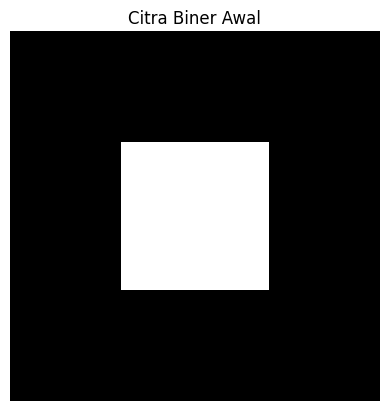

In [51]:
# Membuat citra biner sederhana
image = np.zeros((10,10), dtype=np.uint8)
image[3:7,3:7] = 255

plt.imshow(image, cmap='gray')
plt.title('Citra Biner Awal')
plt.axis('off')
plt.show()

In [72]:
kernel = np.ones((3,3), np.uint8)
print(kernel)

kernel2 = np.ones((16,16), np.uint8)
print(kernel2)

[[1 1 1]
 [1 1 1]
 [1 1 1]]
[[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]]


(np.float64(-0.5), np.float64(199.5), np.float64(199.5), np.float64(-0.5))

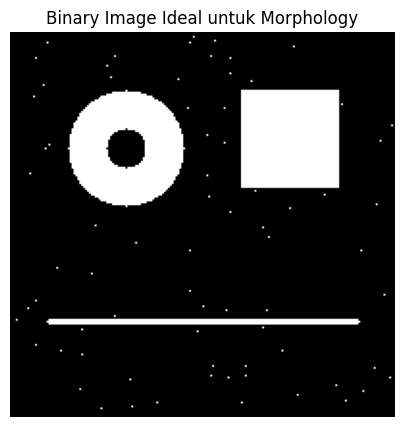

In [59]:
# canvas kosong
img = np.zeros((200,200), dtype=np.uint8)

# =====================
# 1. OBJEK UTAMA
# =====================
# lingkaran besar
cv2.circle(img,(60,60),30,255,-1)
# kotak
cv2.rectangle(img,(120,30),(170,80),255,-1)
# garis tipis
cv2.line(img,(20,150),(180,150),255,2)

# =====================
# 2. LUBANG (untuk Closing)
# =====================
cv2.circle(img,(60,60),10,0,-1)

# =====================
# 3. NOISE KECIL (untuk Opening)
# =====================
noise_points = np.random.randint(0,200,(80,2))
for x,y in noise_points:
    img[y,x] = 255

# =====================
# DISPLAY
# =====================
plt.figure(figsize=(5,5))
plt.imshow(img,cmap='gray')
plt.title("Binary Image Ideal untuk Morphology")
plt.axis('off')

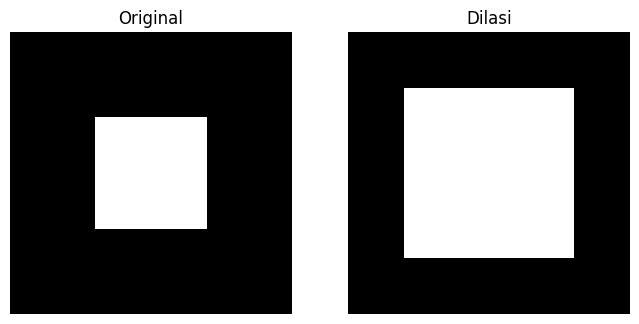

In [52]:
dilation = cv2.dilate(image, kernel, iterations=1)

plt.figure(figsize=(8,4))
plt.subplot(1,2,1)
plt.imshow(image, cmap='gray')
plt.title('Original')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(dilation, cmap='gray')
plt.title('Dilasi')
plt.axis('off')
plt.show()

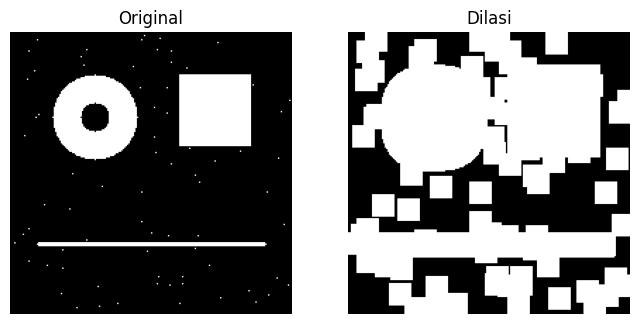

In [77]:
dilation = cv2.dilate(img, kernel2, iterations=1)

plt.figure(figsize=(8,4))
plt.subplot(1,2,1)
plt.imshow(img, cmap='gray')
plt.title('Original')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(dilation, cmap='gray')
plt.title('Dilasi')
plt.axis('off')
plt.show()

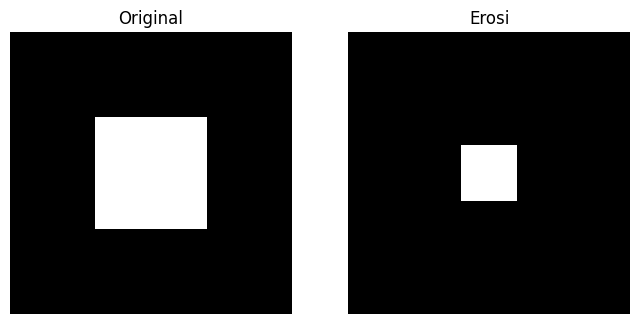

In [53]:
erosion = cv2.erode(image, kernel, iterations=1)

plt.figure(figsize=(8,4))
plt.subplot(1,2,1)
plt.imshow(image, cmap='gray')
plt.title('Original')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(erosion, cmap='gray')
plt.title('Erosi')
plt.axis('off')
plt.show()

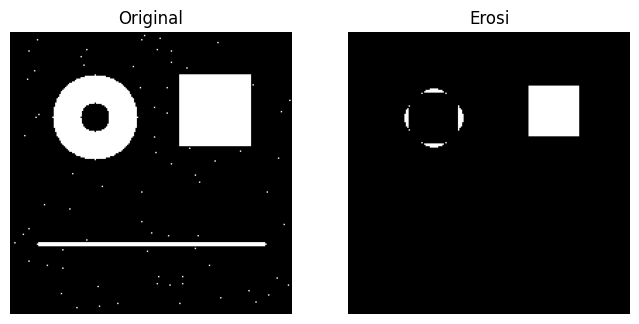

In [76]:
erosion = cv2.erode(img, kernel2, iterations=1)

plt.figure(figsize=(8,4))
plt.subplot(1,2,1)
plt.imshow(img, cmap='gray')
plt.title('Original')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(erosion, cmap='gray')
plt.title('Erosi')
plt.axis('off')
plt.show()

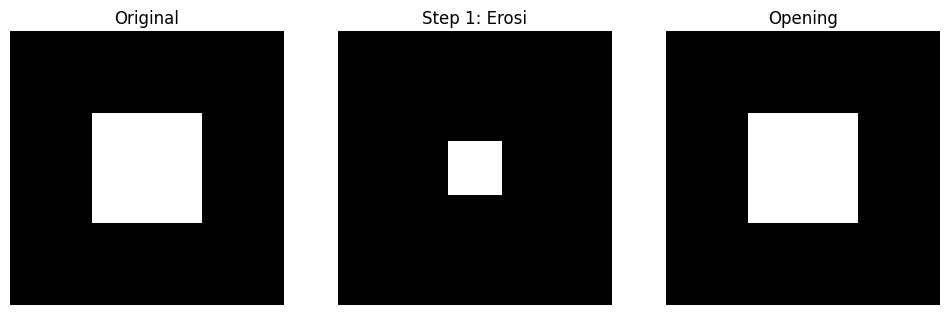

In [54]:
opening = cv2.morphologyEx(image, cv2.MORPH_OPEN, kernel)

plt.figure(figsize=(12,4))
plt.subplot(1,3,1)
plt.imshow(image, cmap='gray')
plt.title('Original')
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(erosion, cmap='gray')
plt.title('Step 1: Erosi')
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(opening, cmap='gray')
plt.title('Opening')
plt.axis('off')
plt.show()

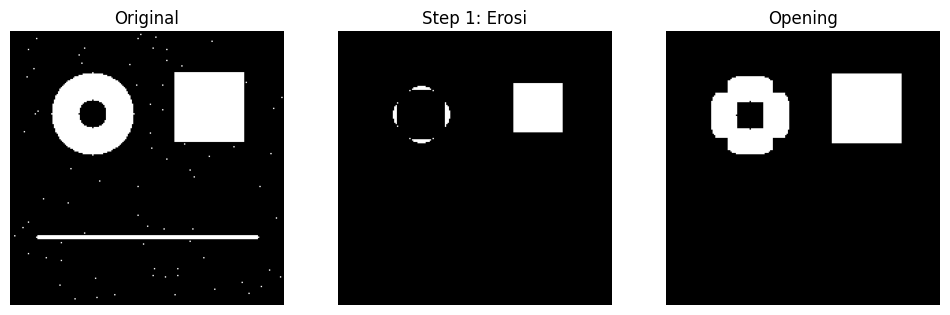

In [78]:
opening = cv2.morphologyEx(img, cv2.MORPH_OPEN, kernel2)

plt.figure(figsize=(12,4))
plt.subplot(1,3,1)
plt.imshow(img, cmap='gray')
plt.title('Original')
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(erosion, cmap='gray')
plt.title('Step 1: Erosi')
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(opening, cmap='gray')
plt.title('Opening')
plt.axis('off')
plt.show()

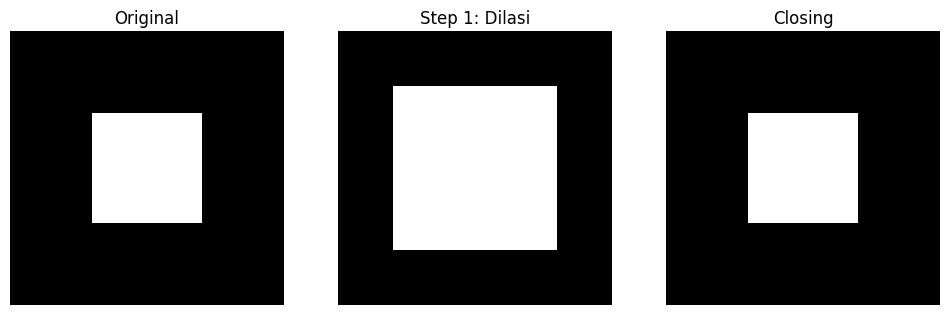

In [55]:
closing = cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel)

plt.figure(figsize=(12,4))
plt.subplot(1,3,1)
plt.imshow(image, cmap='gray')
plt.title('Original')
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(dilation, cmap='gray')
plt.title('Step 1: Dilasi')
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(closing, cmap='gray')
plt.title('Closing')
plt.axis('off')
plt.show()

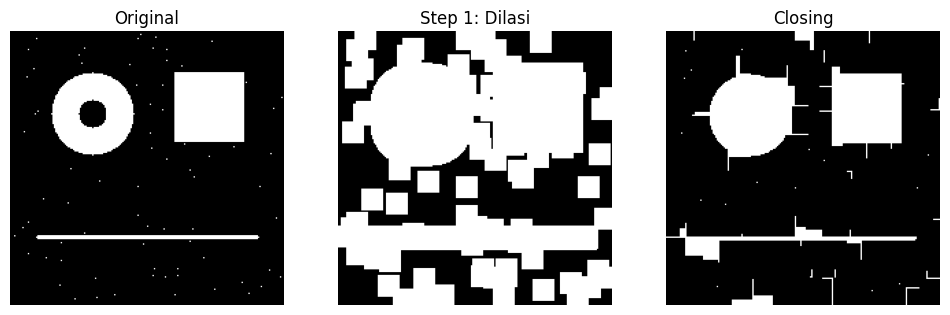

In [79]:
closing = cv2.morphologyEx(img, cv2.MORPH_CLOSE, kernel2)

plt.figure(figsize=(12,4))
plt.subplot(1,3,1)
plt.imshow(img, cmap='gray')
plt.title('Original')
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(dilation, cmap='gray')
plt.title('Step 1: Dilasi')
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(closing, cmap='gray')
plt.title('Closing')
plt.axis('off')
plt.show()

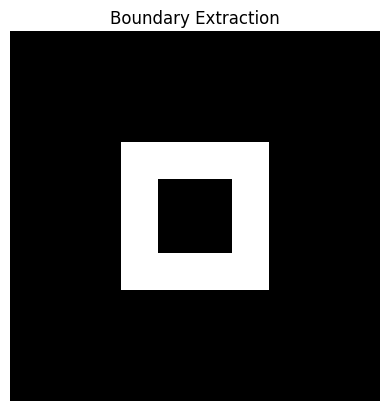

In [56]:
boundary = image - erosion

plt.imshow(boundary, cmap='gray')
plt.title('Boundary Extraction')
plt.axis('off')
plt.show()

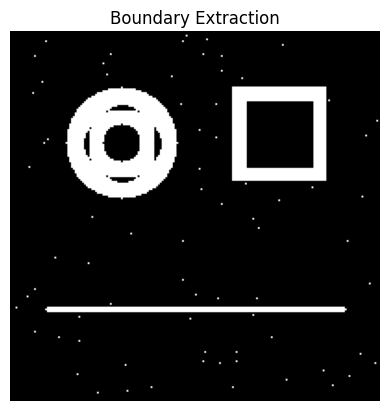

In [80]:
boundary = img - erosion

plt.imshow(boundary, cmap='gray')
plt.title('Boundary Extraction')
plt.axis('off')
plt.show()

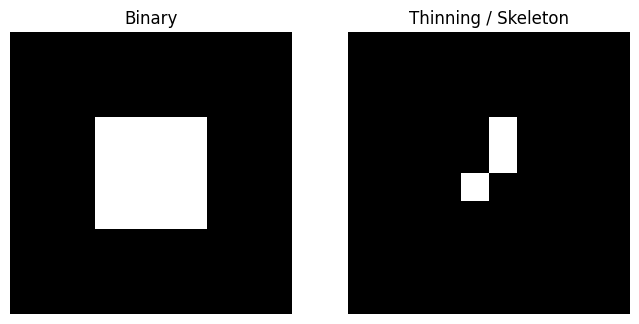

In [57]:
from skimage.morphology import skeletonize

binary = image > 0
skeleton = skeletonize(binary)

plt.figure(figsize=(8,4))
plt.subplot(1,2,1)
plt.imshow(binary, cmap='gray')
plt.title('Binary')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(skeleton, cmap='gray')
plt.title('Thinning / Skeleton')
plt.axis('off')
plt.show()

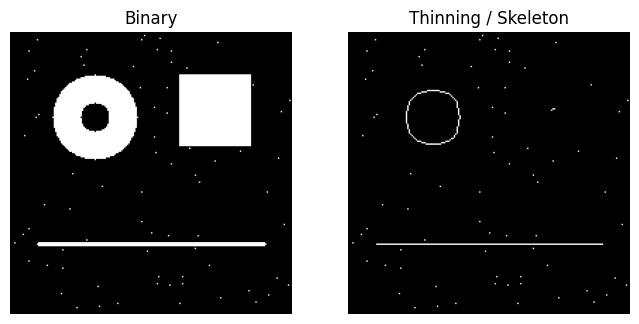

In [81]:
from skimage.morphology import skeletonize

binary = img > 0
skeleton = skeletonize(binary)

plt.figure(figsize=(8,4))
plt.subplot(1,2,1)
plt.imshow(binary, cmap='gray')
plt.title('Binary')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(skeleton, cmap='gray')
plt.title('Thinning / Skeleton')
plt.axis('off')
plt.show()

---

# Eksperimen

(np.float64(-0.5), np.float64(119.5), np.float64(119.5), np.float64(-0.5))

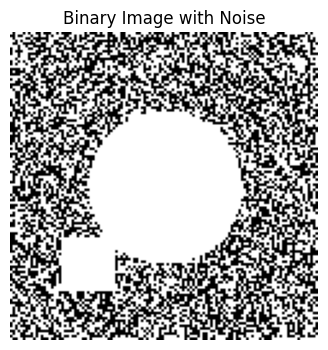

In [82]:
img = np.zeros((120,120), dtype=np.uint8)

# objek utama
cv2.circle(img,(60,60),30,255,-1)
cv2.rectangle(img,(20,80),(40,100),255,-1)

# tambah noise
noise = np.random.randint(0,2,(120,120))*255
img_noisy = cv2.bitwise_or(img, noise.astype(np.uint8))

plt.figure(figsize=(4,4))
plt.imshow(img_noisy, cmap='gray')
plt.title('Binary Image with Noise')
plt.axis('off')

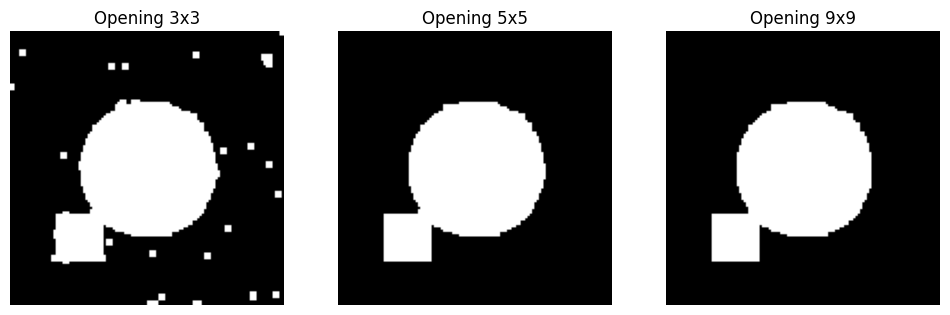

In [83]:
sizes = [3,5,9]

plt.figure(figsize=(12,4))

for i,s in enumerate(sizes):
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT,(s,s))
    result = cv2.morphologyEx(img_noisy, cv2.MORPH_OPEN, kernel)

    plt.subplot(1,3,i+1)
    plt.imshow(result,cmap='gray')
    plt.title(f'Opening {s}x{s}')
    plt.axis('off')

plt.show()

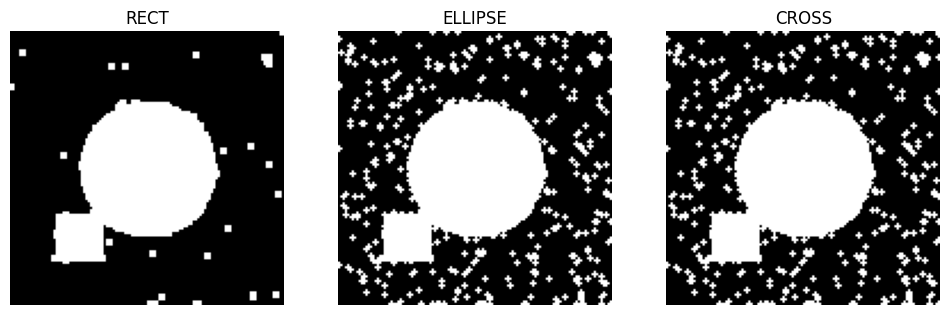

In [84]:
kernels = {
    "RECT": cv2.getStructuringElement(cv2.MORPH_RECT,(3,3)),
    "ELLIPSE": cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(3,3)),
    "CROSS": cv2.getStructuringElement(cv2.MORPH_CROSS,(3,3))
}

plt.figure(figsize=(12,4))

for i,(name,kernel) in enumerate(kernels.items()):
    result = cv2.morphologyEx(img_noisy, cv2.MORPH_OPEN, kernel)

    plt.subplot(1,3,i+1)
    plt.imshow(result,cmap='gray')
    plt.title(name)
    plt.axis('off')

plt.show()

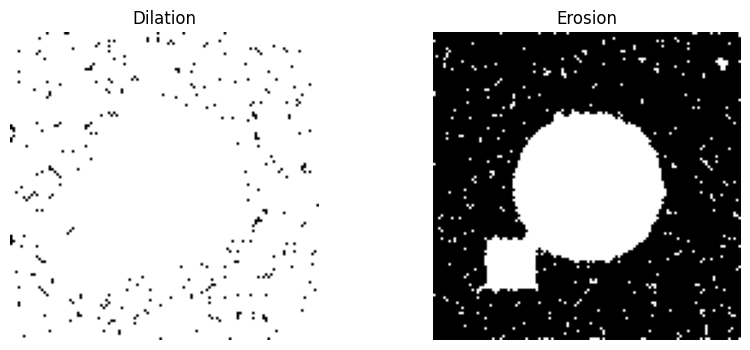

In [97]:
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(3,3))

dilation = cv2.dilate(img_noisy, kernel)
erosion = cv2.erode(img_noisy, kernel)

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.imshow(dilation,cmap='gray')
plt.title('Dilation')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(erosion,cmap='gray')
plt.title('Erosion')
plt.axis('off')

plt.show()

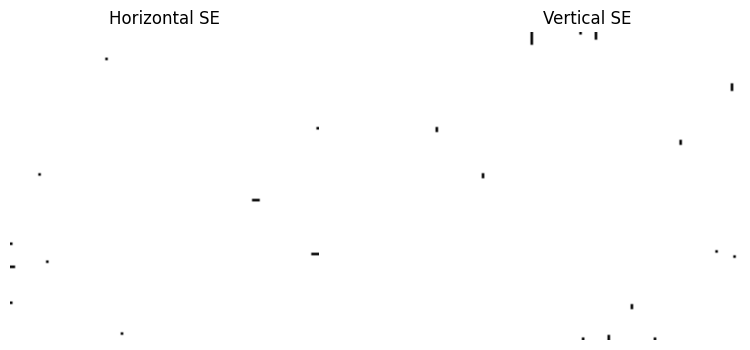

In [96]:
line_kernel = np.zeros((9,9),dtype=np.uint8)
line_kernel[4,:] = 1   # horizontal

horizontal = cv2.dilate(img_noisy, line_kernel)
vertical = cv2.dilate(img_noisy, line_kernel.T)

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.imshow(horizontal,cmap='gray')
plt.title('Horizontal SE')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(vertical,cmap='gray')
plt.title('Vertical SE')
plt.axis('off')

plt.show()

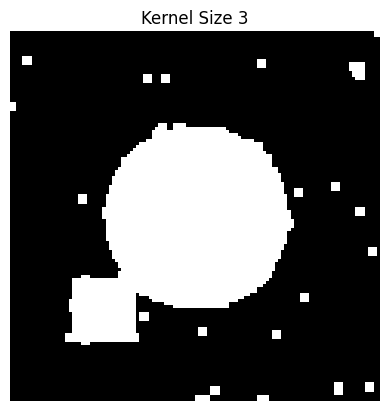

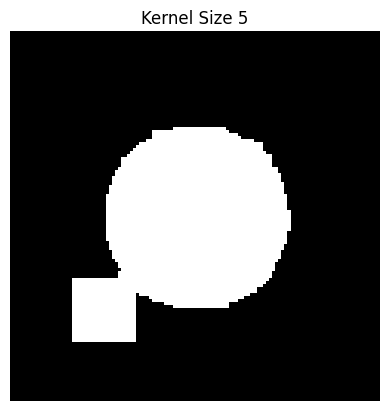

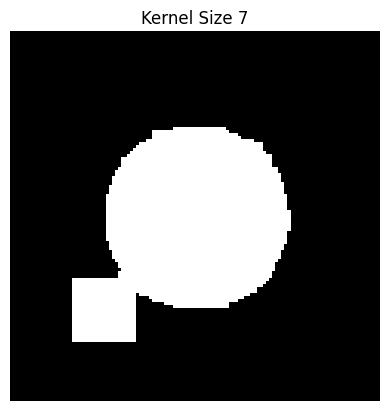

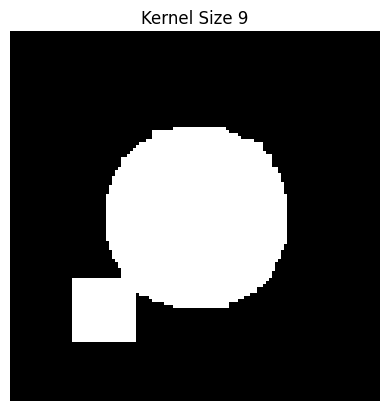

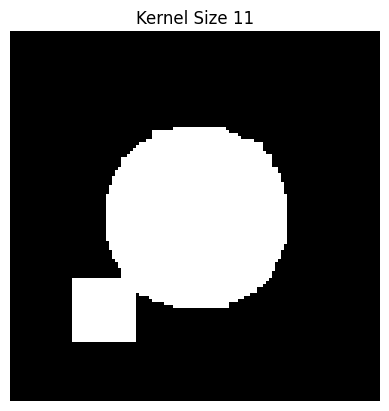

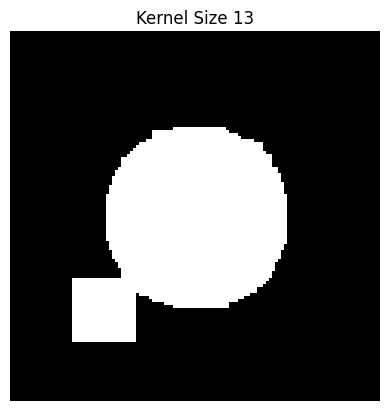

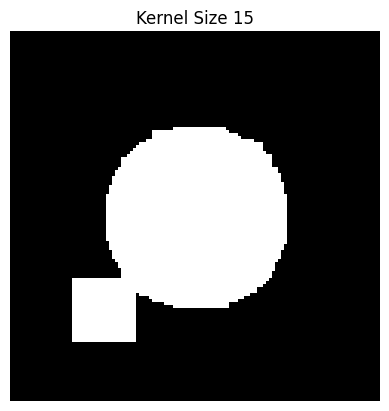

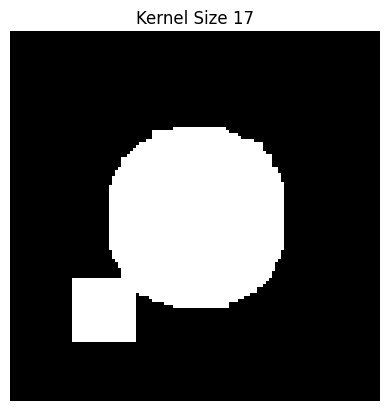

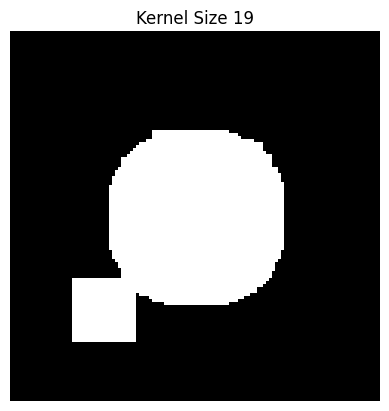

In [88]:
for k in range(3,20,2):
    kernel = np.ones((k,k),np.uint8)
    result = cv2.morphologyEx(img_noisy,
                              cv2.MORPH_OPEN,
                              kernel)

    plt.figure()
    plt.imshow(result,cmap='gray')
    plt.title(f'Kernel Size {k}')
    plt.axis('off')

---

# Coba Citra

(np.float64(-0.5), np.float64(797.5), np.float64(798.5), np.float64(-0.5))

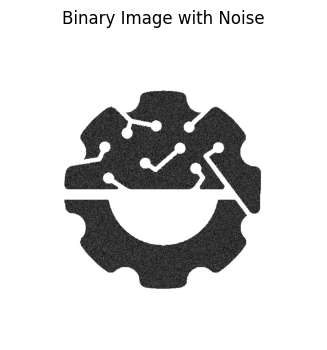

In [113]:
rka_img = "RKA.png"
gray_img = cv2.imread(rka_img, cv2.IMREAD_GRAYSCALE)

# atur threshold agar jadi citra biner
_, gray_img = cv2.threshold(gray_img, 180, 255, cv2.THRESH_BINARY)

# tambah noise dengan dimensi sesuai gambar
h, w = gray_img.shape
noise = np.random.randint(0, 100, (h, w))
img_noisy = cv2.add(gray_img, noise.astype(np.uint8))

plt.figure(figsize=(4,4))
plt.imshow(img_noisy, cmap='gray')
plt.title('Binary Image with Noise')
plt.axis('off')